# ADS / AKIB3 — Klassifikation, Regression und Regularisierung
**Bachelor-Übungen mit Python (28.11.2026) — ausführbare NumPy-Ausgabe**

Dieses Notebook verbindet binäre Klassifikation, Modellbewertung und
Regularisierung bei Regression. Wir beginnen mit einfachen Beispielen und
steigern den Schwierigkeitsgrad schrittweise.

**Wichtig für die Ausführung:** Dieses Notebook verwendet nur **NumPy, pandas und
Matplotlib**. **scikit-learn wird an keiner Stelle importiert oder benötigt.**
Die Modelle sind bewusst vereinfachte, transparent programmierte **Lehrimplementierungen**.
Sie veranschaulichen dieselben statistischen Konzepte, ersetzen aber keine
vollständige Bibliothek für produktive Anwendungen.

Alle Datensätze werden lokal und reproduzierbar simuliert. Kein Internet und
keine zusätzliche Installation sind nötig, sofern die drei genannten Pakete
bereits importiert werden können.

**Merke:** Trainings-, Validierungs- und Testdaten erfüllen unterschiedliche Aufgaben.

## 0. Vorbereitung

- `numpy` arbeitet mit numerischen Feldern und linearer Algebra.
- `pandas` stellt Ergebnisse als übersichtliche Tabellen dar.
- `matplotlib` zeichnet Grafiken.

**Keine scikit-learn-Abhängigkeit:** Die benötigten mathematischen Verfahren
werden unten mit verständlichen Python-Funktionen erklärt.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Die Zufallszahlen werden an den relevanten Stellen jeweils fest gesetzt.
# So ergeben sich bei jedem vollständigen Notebook-Durchlauf dieselben Daten.
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Start erfolgreich – scikit-learn wird nicht benötigt.")

NumPy: 2.0.2
pandas: 2.2.3
Matplotlib: 3.10.8
Start erfolgreich – scikit-learn wird nicht benötigt.


## 1. Mini-Beispiel: Wahrscheinlichkeit und Schwellenwert

Ein Klassifikationsmodell liefert häufig eine Wahrscheinlichkeit,
etwa 0,75 für „Ja“.

Erst ein **Schwellenwert** verwandelt diese Zahl in eine Klasse.
Das ist eine Entscheidung — keine Eigenschaft der Daten.

In [5]:
wahrscheinlichkeiten = np.array([0.10, 0.45, 0.55, 0.90])

for schwelle in [0.3, 0.5, 0.8]:
    entscheidungen = (wahrscheinlichkeiten >= schwelle).astype(int)
    print(f"Schwelle {schwelle:.1f}: {entscheidungen}")

Schwelle 0.3: [0 1 1 1]
Schwelle 0.5: [0 0 1 1]
Schwelle 0.8: [0 0 0 1]


## 2. Warum Accuracy täuschen kann

Stellen wir uns 80 Studierende ohne Risiko und 20 mit Risiko vor.

Ein Modell sagt immer „kein Risiko“. Es ist zu 80 % korrekt,
erkennt aber **niemanden** aus der Risikogruppe.

In [6]:
# Zuerst programmieren wir die Kennzahlen selbst.
# Dadurch wird deutlich, welche Fälle in den Zählern und Nennern stehen.
def confusion_matrix(wahr, vorhersage):
    wahr, vorhersage = np.asarray(wahr), np.asarray(vorhersage)
    tn = int(np.sum((wahr == 0) & (vorhersage == 0)))
    fp = int(np.sum((wahr == 0) & (vorhersage == 1)))
    fn = int(np.sum((wahr == 1) & (vorhersage == 0)))
    tp = int(np.sum((wahr == 1) & (vorhersage == 1)))
    return np.array([[tn, fp], [fn, tp]])

def accuracy_score(wahr, vorhersage):
    return float(np.mean(np.asarray(wahr) == np.asarray(vorhersage)))

def precision_score(wahr, vorhersage):
    tn, fp, fn, tp = confusion_matrix(wahr, vorhersage).ravel()
    return tp / (tp + fp) if tp + fp else 0.0

def recall_score(wahr, vorhersage):
    tn, fp, fn, tp = confusion_matrix(wahr, vorhersage).ravel()
    return tp / (tp + fn) if tp + fn else 0.0

def f1_score(wahr, vorhersage):
    p, r = precision_score(wahr, vorhersage), recall_score(wahr, vorhersage)
    return 2 * p * r / (p + r) if p + r else 0.0

wahr = np.array([0] * 80 + [1] * 20)
prognose = np.zeros(100, dtype=int)
print("Accuracy:", accuracy_score(wahr, prognose))
print("Recall der Klasse 1:", recall_score(wahr, prognose))

Accuracy: 0.8
Recall der Klasse 1: 0.0


## 3. Verwechslungsmatrix, Precision und Recall

- **Precision:** Wie viele positiv vorhergesagte Fälle sind tatsächlich positiv?
- **Recall:** Wie viele tatsächlich positive Fälle wurden gefunden?
- **F1:** Harmonisches Mittel aus Precision und Recall.

In [7]:
y_klein = np.array([0, 0, 0, 0, 1, 1, 1, 1])
p_klein = np.array([0, 0, 1, 0, 1, 0, 1, 1])

print("Verwechslungsmatrix [TN, FP; FN, TP]:")
print(confusion_matrix(y_klein, p_klein))
print("Precision:", round(precision_score(y_klein, p_klein), 3))
print("Recall:", round(recall_score(y_klein, p_klein), 3))
print("F1:", round(f1_score(y_klein, p_klein), 3))

Verwechslungsmatrix [TN, FP; FN, TP]:
[[3 1]
 [1 3]]
Precision: 0.75
Recall: 0.75
F1: 0.75


## 4. Klassifikationsdaten erzeugen

Wir simulieren vier Merkmale für 600 Beobachtungen. Genau 25 % gehören zu
Klasse 1. Die drei ersten Merkmale hängen teilweise mit der Zielklasse zusammen;
das vierte enthält weitgehend Rauschen.

**Einfacher Gedanke:** Positive Fälle erhalten im Mittel bei mehreren Merkmalen
höhere Werte. Das Modell muss diese Unterschiede lernen.

In [8]:
# Eine transparente Alternative zu make_classification aus scikit-learn.
rng_k = np.random.default_rng(42)
y_k = np.r_[np.zeros(450, dtype=int), np.ones(150, dtype=int)]
X_k = rng_k.normal(size=(600, 4))

# Klasse 1 hat im Mittel andere Merkmalswerte als Klasse 0.
X_k[:, 0] += 1.25 * y_k
X_k[:, 1] += 1.00 * y_k
X_k[:, 2] += 0.85 * y_k
# Merkmal 4 bleibt ein zufälliges, nicht informatives Merkmal.

# Durchmischen verhindert, dass die Klassen blockweise angeordnet bleiben.
reihenfolge = rng_k.permutation(len(y_k))
X_k, y_k = X_k[reihenfolge], y_k[reihenfolge]

print("Datenform:", X_k.shape)
print("Klassenhäufigkeiten:", np.bincount(y_k))

Datenform: (600, 4)
Klassenhäufigkeiten: [450 150]


## 5. Training, Validierung und Test

Die Aufteilung verhindert, dass wir die Leistung auf bekannten
Daten überschätzen.

- **Training:** Parameter lernen.
- **Validierung:** Modell und Schwellenwert auswählen.
- **Test:** Abschließende unabhängige Bewertung.

In [9]:
def stratifiziert_aufteilen(X, y, testanteil, zufall=42):
    """In beiden Teilmengen bleibt der Klassenanteil nahezu identisch."""
    rng = np.random.default_rng(zufall)
    train, test = [], []
    for klasse in np.unique(y):
        idx = np.where(y == klasse)[0]
        rng.shuffle(idx)
        n_test = int(round(len(idx) * testanteil))
        test.extend(idx[:n_test])
        train.extend(idx[n_test:])
    train, test = np.asarray(train), np.asarray(test)
    rng.shuffle(train)
    rng.shuffle(test)
    return X[train], X[test], y[train], y[test]

# Zuerst 20 % als unabhängige Testmenge reservieren.
X_k_entw, X_k_test, y_k_entw, y_k_test = stratifiziert_aufteilen(
    X_k, y_k, testanteil=0.20, zufall=42
)
# Von den übrigen 80 % gehen 25 % in die Validierung (also 20 % insgesamt).
X_k_train, X_k_val, y_k_train, y_k_val = stratifiziert_aufteilen(
    X_k_entw, y_k_entw, testanteil=0.25, zufall=43
)
print("Training:", len(y_k_train))
print("Validierung:", len(y_k_val))
print("Test:", len(y_k_test))
print("Anteil Klasse 1 je Teil:",
      np.round([y_k_train.mean(), y_k_val.mean(), y_k_test.mean()], 3))

Training: 360
Validierung: 120
Test: 120
Anteil Klasse 1 je Teil: [0.25 0.25 0.25]


## 6. Logistische Regression (einfach implementiert)

Die logistische Regression sagt eine **Wahrscheinlichkeit für Klasse 1** voraus:
Die Sigmoidfunktion wandelt einen linearen Modellwert in eine Zahl zwischen
0 und 1 um.

**Standardisierung:** Von jedem Merkmal wird der Trainingsmittelwert abgezogen
und durch die Trainingsstandardabweichung geteilt. Bei den Validierungs- und
Testdaten verwenden wir **genau diese Trainingswerte** (kein Data Leakage).

Die Modellgewichte werden hier mit dem Newton-Verfahren angepasst. Eine kleine
L2-Strafe stabilisiert die Berechnung. Das Beispiel zeigt die Grundidee, nicht
alle Funktionen von scikit-learn.

Erste Wahrscheinlichkeiten: [0.935 0.671 0.597 0.001 0.71  0.076 0.997 0.005]


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: divide by zero encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: overflow encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: invalid value encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: divide by zero encountered in matmul
  hessian = Z.T @ (varianz[:, None] * Z) + strafmatrix
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: overflow encountered in matmul
  hessian = Z.T @ (varianz[:, None] * Z) + strafmatrix
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: invalid value encountered in matmul
  hessian = Z.T @ (varianz[:, None] *

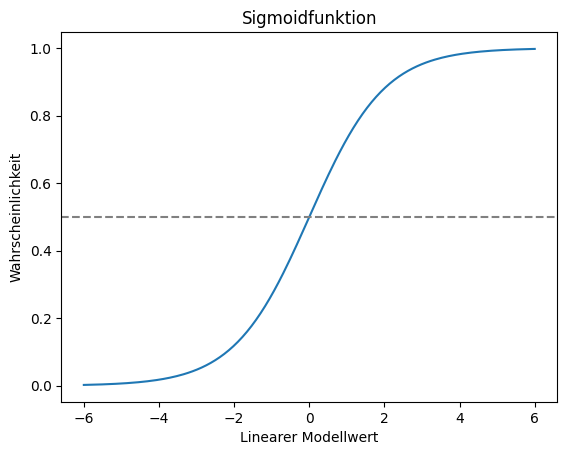

In [10]:
def standardisierung_lernen(X):
    # Mittelwert und Streuung werden NUR auf der Trainingsmenge gelernt.
    mittel = np.mean(X, axis=0)
    streuung = np.std(X, axis=0)
    streuung = np.where(streuung < 1e-12, 1.0, streuung)
    return mittel, streuung

def sigmoid(z):
    # Begrenzung vermeidet numerischen Überlauf bei sehr großen Werten.
    z = np.clip(z, -40, 40)
    return 1.0 / (1.0 + np.exp(-z))

def logit_trainieren(X, y, ausgleich=False, l2=0.7, max_schritte=35):
    """Lehrimplementierung einer logistischen Regression (Newton-Verfahren)."""
    mittel, streuung = standardisierung_lernen(X)
    Z = np.column_stack((np.ones(len(X)), (X - mittel) / streuung))
    y = np.asarray(y, dtype=float)

    # Optional: seltene und häufige Klassen erhalten gleiches Gesamtgewicht.
    if ausgleich:
        n_pos, n_neg = np.sum(y == 1), np.sum(y == 0)
        gewichte_faelle = np.where(y == 1, len(y)/(2*n_pos), len(y)/(2*n_neg))
    else:
        gewichte_faelle = np.ones(len(y))

    b = np.zeros(Z.shape[1])
    strafmatrix = np.diag([0.0] + [l2] * (Z.shape[1] - 1))
    for _ in range(max_schritte):
        p = sigmoid(Z @ b)
        gradient = Z.T @ (gewichte_faelle * (y - p)) - strafmatrix @ b
        varianz = gewichte_faelle * p * (1 - p)
        hessian = Z.T @ (varianz[:, None] * Z) + strafmatrix
        schritt = np.linalg.solve(hessian, gradient)
        b += schritt
        if np.max(np.abs(schritt)) < 1e-8:
            break
    return {"gewichte": b, "mittel": mittel, "streuung": streuung}

def logit_wahrscheinlichkeit(modell, X):
    X_st = (X - modell["mittel"]) / modell["streuung"]
    Z = np.column_stack((np.ones(len(X_st)), X_st))
    return sigmoid(Z @ modell["gewichte"])

modell_logit = logit_trainieren(X_k_train, y_k_train)
p_val = logit_wahrscheinlichkeit(modell_logit, X_k_val)
print("Erste Wahrscheinlichkeiten:", np.round(p_val[:8], 3))

z = np.linspace(-6, 6, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls="--", color="gray")
plt.title("Sigmoidfunktion")
plt.xlabel("Linearer Modellwert")
plt.ylabel("Wahrscheinlichkeit")
plt.show()

## 7. Klassenungleichgewicht: gewichtete logistische Regression

Wenn Klasse 1 selten ist, können wir Fehler bei dieser Klasse stärker gewichten.
Dafür verwenden wir bei der Schätzung ein höheres Gewicht für seltene Fälle.
Das ist vergleichbar mit der Idee `class_weight="balanced"` in scikit-learn,
aber hier direkt mit NumPy umgesetzt.

Das führt nicht automatisch zu einem besseren Modell. Oft steigt Recall,
während Precision sinkt.

In [11]:
modell_bal = logit_trainieren(X_k_train, y_k_train, ausgleich=True)

for name, modell in [("Standard", modell_logit), ("Gewichtet", modell_bal)]:
    # Klassenzuordnung mit Standard-Schwellenwert 0,5.
    pr = (logit_wahrscheinlichkeit(modell, X_k_val) >= 0.5).astype(int)
    print(name,
          "Precision:", round(precision_score(y_k_val, pr), 3),
          "Recall:", round(recall_score(y_k_val, pr), 3))

Standard Precision: 0.812 Recall: 0.867
Gewichtet Precision: 0.667 Recall: 1.0


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: divide by zero encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: overflow encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: invalid value encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: divide by zero encountered in matmul
  hessian = Z.T @ (varianz[:, None] * Z) + strafmatrix
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: overflow encountered in matmul
  hessian = Z.T @ (varianz[:, None] * Z) + strafmatrix
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:32: RuntimeWarning: invalid value encountered in matmul
  hessian = Z.T @ (varianz[:, None] *

## 8. Schwellenwert anhand der Validierung auswählen

Wir vergleichen Schwellenwerte zwischen 0,1 und 0,9.

Wir wählen den Schwellenwert mit dem höchsten **F1-Wert**.

**Wichtig:** Den Schwellenwert nicht anhand der Testdaten optimieren.

Beste Schwelle: 0.45


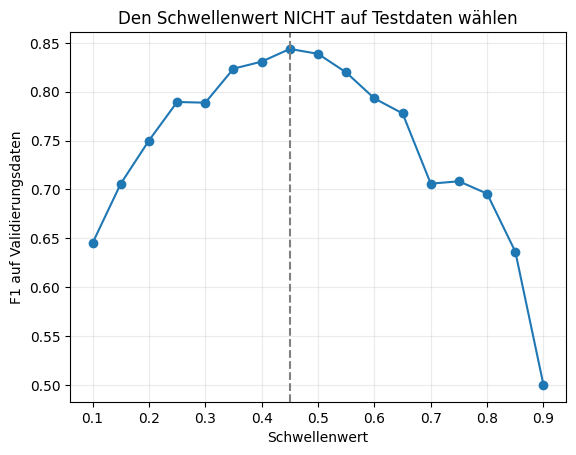

In [12]:
# Die Auswahl erfolgt ausschließlich anhand der Validierungsdaten.
schwellen = np.linspace(0.1, 0.9, 17)
f1_liste = [f1_score(y_k_val, (p_val >= s).astype(int)) for s in schwellen]
beste_schwelle = float(schwellen[np.argmax(f1_liste)])
print("Beste Schwelle:", round(beste_schwelle, 2))

plt.plot(schwellen, f1_liste, marker="o")
plt.axvline(beste_schwelle, ls="--", color="gray")
plt.xlabel("Schwellenwert")
plt.ylabel("F1 auf Validierungsdaten")
plt.title("Den Schwellenwert NICHT auf Testdaten wählen")
plt.grid(alpha=0.25)
plt.show()

## 9. Abschließende Auswertung auf Testdaten

Nach der Auswahl des Schwellenwertes prüfen wir das Modell
an zuvor zurückgehaltenen Daten.

Damit wird die Vorhersageleistung realistischer geschätzt.

Accuracy     0.842
Precision    0.657
Recall       0.767
F1           0.708
ROC AUC      0.873
dtype: float64


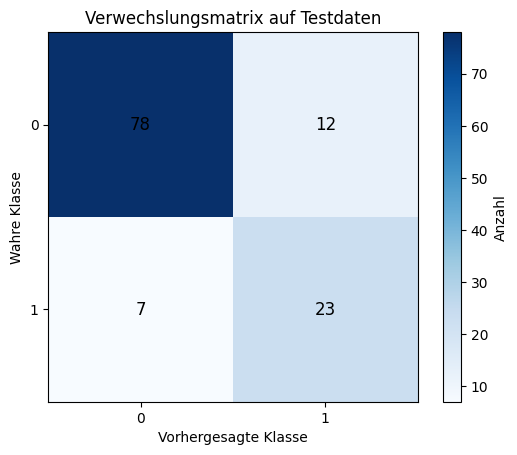

In [13]:
def roc_auc_score(wahr, p):
    """AUC als Anteil korrekt geordneter Positiv-Negativ-Paare."""
    wahr, p = np.asarray(wahr), np.asarray(p)
    positive = p[wahr == 1]
    negative = p[wahr == 0]
    if not len(positive) or not len(negative):
        return float("nan")
    # Bei Gleichständen zählt ein Paar nur zur Hälfte.
    return float(np.mean((positive[:, None] > negative[None, :]) +
                         0.5 * (positive[:, None] == negative[None, :])))

p_test = logit_wahrscheinlichkeit(modell_logit, X_k_test)
y_test_hat = (p_test >= beste_schwelle).astype(int)

metriken = pd.Series({
    "Accuracy": accuracy_score(y_k_test, y_test_hat),
    "Precision": precision_score(y_k_test, y_test_hat),
    "Recall": recall_score(y_k_test, y_test_hat),
    "F1": f1_score(y_k_test, y_test_hat),
    "ROC AUC": roc_auc_score(y_k_test, p_test)
})
print(metriken.round(3))

# Verwechslungsmatrix ohne zusätzliche Bibliothek zeichnen.
cm = confusion_matrix(y_k_test, y_test_hat)
plt.imshow(cm, cmap="Blues")
for zeile in range(2):
    for spalte in range(2):
        plt.text(spalte, zeile, str(cm[zeile, spalte]),
                 ha="center", va="center", fontsize=12)
plt.xticks([0, 1], ["0", "1"])
plt.yticks([0, 1], ["0", "1"])
plt.xlabel("Vorhergesagte Klasse")
plt.ylabel("Wahre Klasse")
plt.title("Verwechslungsmatrix auf Testdaten")
plt.colorbar(label="Anzahl")
plt.show()

## 10. ROC- und Precision-Recall-Kurven

Die ROC-Kurve vergleicht Trefferquote und Fehlalarmrate
bei vielen verschiedenen Schwellenwerten.

Die Precision-Recall-Kurve ist besonders informativ,
wenn positive Fälle selten sind.

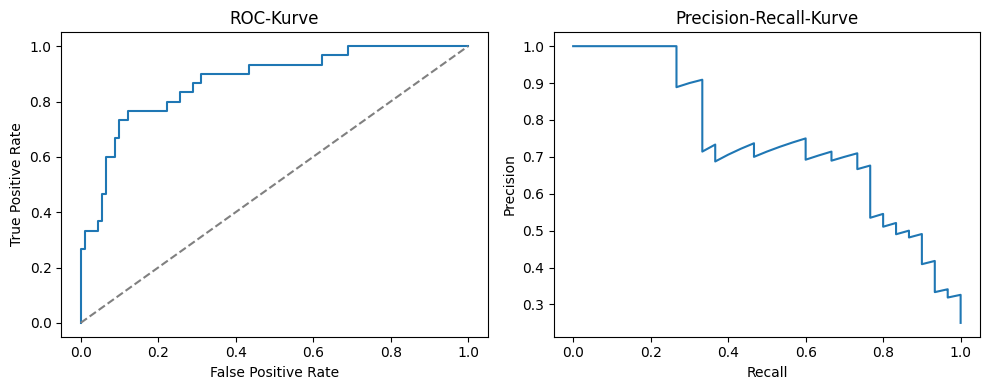

In [14]:
def kurvenpunkte(wahr, wahrscheinlichkeiten):
    """ROC und Precision-Recall für alle unterschiedlichen Schwellen berechnen."""
    schwellen = np.r_[np.inf, np.sort(np.unique(wahrscheinlichkeiten))[::-1]]
    n_pos = np.sum(np.asarray(wahr) == 1)
    n_neg = np.sum(np.asarray(wahr) == 0)
    fpr, tpr, precision, recall = [], [], [], []
    for grenze in schwellen:
        vorhersage = (wahrscheinlichkeiten >= grenze).astype(int)
        tn, fp, fn, tp = confusion_matrix(wahr, vorhersage).ravel()
        fpr.append(fp / n_neg)
        tpr.append(tp / n_pos)
        precision.append(tp / (tp + fp) if tp + fp else 1.0)
        recall.append(tp / n_pos)
    return np.asarray(fpr), np.asarray(tpr), np.asarray(precision), np.asarray(recall)

fpr, tpr, prec, rec = kurvenpunkte(y_k_test, p_test)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC-Kurve")
ax[1].plot(rec, prec)
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall-Kurve")
plt.tight_layout()
plt.show()

## 11. Kalibrierung

Ein Modell ist gut kalibriert, wenn bei Prognosen um 70 %
tatsächlich ungefähr 70 % positive Fälle beobachtet werden.

Der **Brier-Score** misst den durchschnittlichen quadratischen
Fehler der vorhergesagten Wahrscheinlichkeiten.

Brier-Score (kleiner ist besser): 0.119


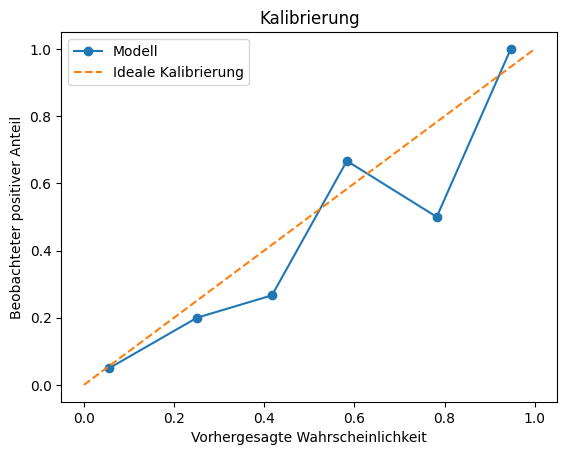

In [15]:
# Jede Wahrscheinlichkeit gehört in eines von sechs Intervallen.
# Beispiel: Prognosen um 0,7 werden mit den tatsächlichen Häufigkeiten verglichen.
def kalibrierung(wahr, p, anzahl_bins=6):
    grenzen = np.linspace(0, 1, anzahl_bins + 1)
    bins = np.clip(np.digitize(p, grenzen[1:-1]), 0, anzahl_bins - 1)
    echte_anteile, prognose_mittel = [], []
    for b in range(anzahl_bins):
        maske = bins == b
        if np.any(maske):
            echte_anteile.append(np.mean(wahr[maske]))
            prognose_mittel.append(np.mean(p[maske]))
    return np.asarray(echte_anteile), np.asarray(prognose_mittel)

anteil, mittlere_prognose = kalibrierung(y_k_test, p_test, anzahl_bins=6)
brier = np.mean((p_test - y_k_test) ** 2)
print("Brier-Score (kleiner ist besser):", round(float(brier), 3))

plt.plot(mittlere_prognose, anteil, marker="o", label="Modell")
plt.plot([0, 1], [0, 1], "--", label="Ideale Kalibrierung")
plt.xlabel("Vorhergesagte Wahrscheinlichkeit")
plt.ylabel("Beobachteter positiver Anteil")
plt.title("Kalibrierung")
plt.legend()
plt.show()

## 12. Entscheidungsgrenze in zwei Dimensionen

Mit zwei Merkmalen können wir visualisieren, auf welcher
Seite einer Trennlinie das Modell Klasse 0 oder 1 vorhersagt.

Reale Anwendungen verwenden häufig deutlich mehr Merkmale.

/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: divide by zero encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: overflow encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:29: RuntimeWarning: invalid value encountered in matmul
  p = sigmoid(Z @ b)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:42: RuntimeWarning: divide by zero encountered in matmul
  return sigmoid(Z @ modell["gewichte"])
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:42: RuntimeWarning: overflow encountered in matmul
  return sigmoid(Z @ modell["gewichte"])
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/968613940.py:42: RuntimeWarning: invalid value encountered in matmul
  return sigmoid(Z @ modell["gewichte"])


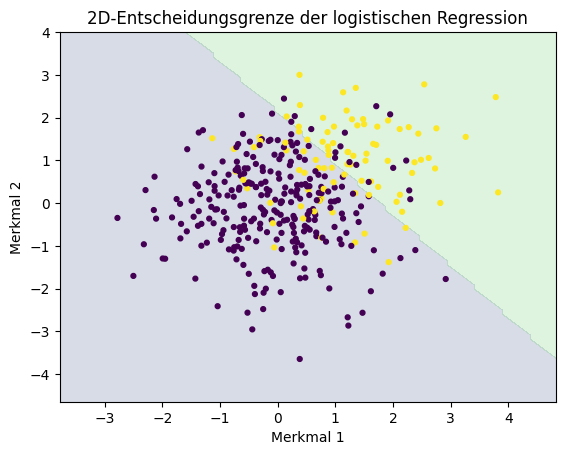

In [16]:
# Nur zwei Merkmale verwenden, damit wir die Grenze zeichnen können.
X2 = X_k_train[:, :2]
mini = logit_trainieren(X2, y_k_train)

xmin, xmax = X2[:, 0].min() - 1, X2[:, 0].max() + 1
ymin, ymax = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 90),
                     np.linspace(ymin, ymax, 90))
punkte = np.column_stack((xx.ravel(), yy.ravel()))
zz = (logit_wahrscheinlichkeit(mini, punkte) >= 0.5).reshape(xx.shape)

plt.contourf(xx, yy, zz, alpha=0.2)
plt.scatter(X2[:, 0], X2[:, 1], c=y_k_train, s=12)
plt.title("2D-Entscheidungsgrenze der logistischen Regression")
plt.xlabel("Merkmal 1")
plt.ylabel("Merkmal 2")
plt.show()

## 13. Koeffizienten verstehen

Ein positiver Koeffizient erhöht bei ansonsten gleichen
Merkmalen den Log-Odds-Wert der Klasse 1.

Bei einer Pipeline mit StandardScaler beziehen sich
die Gewichte auf standardisierte Merkmale.

In [17]:
# Das erste Gewicht ist der Achsenabschnitt (Intercept).
# Die vier weiteren Gewichte beziehen sich auf standardisierte Merkmale.
koeff = modell_logit["gewichte"][1:]
print(pd.Series(koeff, index=[f"Merkmal {i+1}" for i in range(4)]).round(3))

Merkmal 1    1.387
Merkmal 2    1.278
Merkmal 3    0.947
Merkmal 4   -0.296
dtype: float64


## 14. Vergleich mit einem vereinfachten Random Forest

Ein Random Forest kombiniert viele Entscheidungsbäume und kann nichtlineare
Zusammenhänge erfassen. Hier schreiben wir eine **kleine Lehrversion** selbst:

1. Jeder Baum bekommt eine Stichprobe mit Zurücklegen (*Bootstrap*).
2. Pro Aufteilung wird zufällig nur ein Teil der Merkmale betrachtet.
3. Die Bäume sind bewusst flach, damit die Berechnung übersichtlich bleibt.
4. Die vorhergesagten Wahrscheinlichkeiten der Bäume werden gemittelt.

Dies illustriert das Grundprinzip eines Random Forest, ist aber **kein vollständiger
Ersatz** für `RandomForestClassifier` aus scikit-learn.

In [18]:
def gini(y):
    # Reinheit eines Knotens: 0 bedeutet, alle Fälle haben dieselbe Klasse.
    p = np.mean(y)
    return 2 * p * (1 - p)

def baum_lernen(X, y, rng, wichtigkeit, tiefe=0, maximale_tiefe=3):
    """Kleinen binären Entscheidungsbaum anhand der Gini-Unreinheit lernen."""
    blatt = {"p": float(np.mean(y))}
    if tiefe >= maximale_tiefe or len(y) < 16 or gini(y) < 1e-12:
        return blatt

    # Wie im Random Forest: pro Aufteilung nur eine zufällige Merkmalsauswahl.
    merkmale = rng.choice(X.shape[1], size=max(1, int(np.sqrt(X.shape[1]))), replace=False)
    bester_gewinn, beste_info = 0.0, None
    for j in merkmale:
        # Wenige Kandidaten halten dieses Lernbeispiel einfach und schnell.
        for grenze in np.unique(np.quantile(X[:, j], [0.2, 0.4, 0.6, 0.8])):
            links = X[:, j] <= grenze
            n_links, n_rechts = int(links.sum()), int((~links).sum())
            if min(n_links, n_rechts) < 5:
                continue
            verlust = (n_links * gini(y[links]) + n_rechts * gini(y[~links])) / len(y)
            gewinn = gini(y) - verlust
            if gewinn > bester_gewinn:
                bester_gewinn, beste_info = gewinn, (j, float(grenze), links)
    if beste_info is None:
        return blatt
    j, grenze, links = beste_info
    wichtigkeit[j] += bester_gewinn * len(y)
    return {
        "merkmal": j, "grenze": grenze,
        "links": baum_lernen(X[links], y[links], rng, wichtigkeit, tiefe+1, maximale_tiefe),
        "rechts": baum_lernen(X[~links], y[~links], rng, wichtigkeit, tiefe+1, maximale_tiefe)
    }

def baum_wahrscheinlichkeit(baum, ein_fall):
    while "merkmal" in baum:
        baum = baum["links"] if ein_fall[baum["merkmal"]] <= baum["grenze"] else baum["rechts"]
    return baum["p"]

def wald_lernen(X, y, anzahl_baeume=40, zufall=42):
    rng = np.random.default_rng(zufall)
    baeume, wichtigkeit = [], np.zeros(X.shape[1])
    for _ in range(anzahl_baeume):
        bootstrap = rng.integers(0, len(y), size=len(y))
        baeume.append(baum_lernen(X[bootstrap], y[bootstrap], rng, wichtigkeit))
    wichtigkeit /= max(wichtigkeit.sum(), 1e-12)
    return {"baeume": baeume, "wichtigkeit": wichtigkeit}

def wald_wahrscheinlichkeit(wald, X):
    return np.mean([
        [baum_wahrscheinlichkeit(baum, fall) for fall in X]
        for baum in wald["baeume"]
    ], axis=0)

wald = wald_lernen(X_k_train, y_k_train, anzahl_baeume=40)
p_wald_val = wald_wahrscheinlichkeit(wald, X_k_val)
print("ROC AUC – Logit:", round(roc_auc_score(y_k_val, p_val), 3))
print("ROC AUC – Baumensemble:", round(roc_auc_score(y_k_val, p_wald_val), 3))
print("Merkmalswichtigkeiten:", np.round(wald["wichtigkeit"], 3))

ROC AUC – Logit: 0.97
ROC AUC – Baumensemble: 0.957
Merkmalswichtigkeiten: [0.486 0.307 0.188 0.02 ]


# Teil B: Regression und Regularisierung

Bei einer **Regression** prognostizieren wir Zahlen statt Klassen.

Beispiele sind Punktzahlen, Umsätze oder Temperaturen.

## 15. Mini-Beispiel: Lernstunden und Punkte

Ein lineares Modell beschreibt den Zusammenhang durch eine Gerade.

Wir betrachten ein einfaches Beispiel, in dem die Punktzahl
mit den gelernten Stunden steigt.

Steigung: 6.11
Achsenabschnitt: 36.27


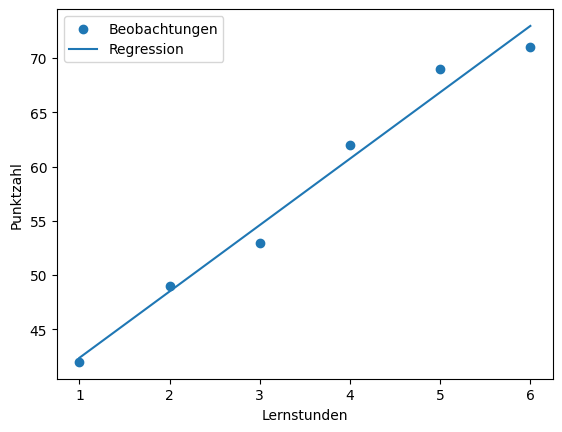

In [19]:
stunden = np.array([1, 2, 3, 4, 5, 6], dtype=float)
punkte = np.array([42, 49, 53, 62, 69, 71], dtype=float)

# Lineare Regression mit der Methode der kleinsten Quadrate:
# Punkte ≈ Achsenabschnitt + Steigung * Stunden
A = np.column_stack((np.ones(len(stunden)), stunden))
achsenabschnitt, steigung = np.linalg.lstsq(A, punkte, rcond=None)[0]
print("Steigung:", round(steigung, 2))
print("Achsenabschnitt:", round(achsenabschnitt, 2))

plt.scatter(stunden, punkte, label="Beobachtungen")
plt.plot(stunden, achsenabschnitt + steigung * stunden, label="Regression")
plt.xlabel("Lernstunden")
plt.ylabel("Punktzahl")
plt.legend()
plt.show()

## 16. Was bedeuten MSE und R²?

Der **Mean Squared Error (MSE)** ist der durchschnittliche
quadratische Vorhersagefehler. Kleinere Werte sind besser.

**R²** beschreibt, wie viel Varianz das Modell im Vergleich
zu einer konstanten Mittelwertprognose erklärt.

In [20]:
def mean_squared_error(wahr, prognose):
    # Mittelwert der quadrierten Abweichungen.
    return float(np.mean((np.asarray(wahr) - np.asarray(prognose))**2))

def r2_score(wahr, prognose):
    # Vergleich mit der konstanten Prognose durch den Stichprobenmittelwert.
    wahr, prognose = np.asarray(wahr), np.asarray(prognose)
    gesamt = np.sum((wahr - np.mean(wahr))**2)
    return float(1 - np.sum((wahr - prognose)**2)/gesamt)

y_wahr = np.array([2., 4., 6.])
y_prognose = np.array([3., 4., 5.])
print("MSE:", mean_squared_error(y_wahr, y_prognose))
print("R²:", round(r2_score(y_wahr, y_prognose), 3))

MSE: 0.6666666666666666
R²: 0.75


## 17. Ridge und Lasso: Einfaches Beispiel

Beide Verfahren bestrafen große Modellkoeffizienten.

- **Ridge:** Quadratische Strafe (L2); lässt sich mit linearer Algebra berechnen.
- **Lasso:** Absolute Strafe (L1); wir verwenden *Koordinatenabstieg*.
- **alpha:** Stärke der Regularisierung.

Lasso kann Gewichte exakt auf null setzen.

**Didaktischer Hinweis:** Wir standardisieren Merkmale jeweils **nur auf
Trainingsdaten** und behandeln den Achsenabschnitt getrennt. Für Ridge verwenden
wir die Summe der quadratischen Fehler plus `alpha * Summe(β²)`. Für Lasso
verwenden wir `MSE/2 + alpha * Summe(|β|)`.

In [21]:
def regression_trainieren(X, y, art="Ridge", alpha=1.0, max_schritte=300):
    """Lineare Regression, Ridge und Lasso – direkt mit NumPy."""
    mittel, streuung = standardisierung_lernen(X)
    Z = (X - mittel) / streuung
    y_mittel = float(np.mean(y))
    ziel = np.asarray(y) - y_mittel
    p = Z.shape[1]

    if art == "Linear":
        koeff = np.linalg.lstsq(Z, ziel, rcond=None)[0]
    elif art == "Ridge":
        # Geschlossene Formel für Ridge (L2-Strafe).
        koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
    elif art == "Lasso":
        # Koordinatenabstieg; Änderung jeweils nur EINES Koeffizienten.
        # Ziel: (1/(2n))*Summe(Fehler²) + alpha*Summe(|Koeffizient|).
        gram = Z.T @ Z
        xy = Z.T @ ziel
        koeff = np.zeros(p)
        rest = xy.copy()  # rest = xy - gram @ koeff
        for _ in range(max_schritte):
            maximale_aenderung = 0.0
            for j in range(p):
                u = rest[j] + gram[j, j] * koeff[j]
                # Soft Thresholding kann ein Gewicht exakt zu null machen.
                neu = np.sign(u) * max(abs(u) - len(y) * alpha, 0.0) / max(gram[j, j], 1e-12)
                delta = neu - koeff[j]
                if abs(delta) > 0:
                    koeff[j] = neu
                    rest -= gram[:, j] * delta
                    maximale_aenderung = max(maximale_aenderung, abs(delta))
            if maximale_aenderung < 1e-7:
                break
    else:
        raise ValueError("art muss 'Linear', 'Ridge' oder 'Lasso' sein")
    return {"art": art, "alpha": alpha, "koeff": koeff,
            "mittel": mittel, "streuung": streuung, "intercept": y_mittel}

def regression_vorhersagen(modell, X):
    return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]

rng = np.random.default_rng(42)
xmini = rng.normal(size=(80, 3))
ymini = 3*xmini[:, 0] - 2*xmini[:, 1] + rng.normal(scale=0.5, size=80)
for name, alpha in [("Linear", 0.0), ("Ridge", 10.0), ("Lasso", 0.3)]:
    modell = regression_trainieren(xmini, ymini, art=name, alpha=alpha)
    print(name, np.round(modell["koeff"], 3))

Linear [ 2.655 -1.862 -0.046]
Ridge [ 2.351 -1.63  -0.084]
Lasso [ 2.335 -1.558  0.   ]


## 18. Größerer Regressionsdatensatz

Wir erzeugen 900 Beobachtungen mit 60 Merkmalen. Nur zwölf Merkmale haben in
unserer Simulation einen echten linearen Einfluss auf die Zielvariable.
Die restlichen 48 Merkmale enthalten unabhängiges Rauschen.

Den Testdatensatz bewahren wir bis zur Schlussbewertung auf.

In [22]:
# NumPy-Version eines künstlichen Regressionsdatensatzes.
rng_r = np.random.default_rng(42)
X_r = rng_r.normal(size=(900, 60))
wahre_gewichte = np.zeros(60)
aktiv = rng_r.choice(60, size=12, replace=False)
wahre_gewichte[aktiv] = rng_r.uniform(25, 90, size=12) * rng_r.choice([-1, 1], size=12)
y_r = X_r @ wahre_gewichte + rng_r.normal(scale=30, size=900)

# Die zufällige Aufteilung erfolgt auf Beobachtungsebene.
idx = rng_r.permutation(len(y_r))
anzahl_test = int(round(len(y_r) * 0.2))
idx_test, idx_train = idx[:anzahl_test], idx[anzahl_test:]
X_r_train, X_r_test = X_r[idx_train], X_r[idx_test]
y_r_train, y_r_test = y_r[idx_train], y_r[idx_test]
print("Trainingsdaten:", X_r_train.shape)
print("Testdaten:", X_r_test.shape)

Trainingsdaten: (720, 60)
Testdaten: (180, 60)


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/4079333350.py:7: RuntimeWarning: divide by zero encountered in matmul
  y_r = X_r @ wahre_gewichte + rng_r.normal(scale=30, size=900)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/4079333350.py:7: RuntimeWarning: overflow encountered in matmul
  y_r = X_r @ wahre_gewichte + rng_r.normal(scale=30, size=900)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/4079333350.py:7: RuntimeWarning: invalid value encountered in matmul
  y_r = X_r @ wahre_gewichte + rng_r.normal(scale=30, size=900)


## 19. Fünffache Kreuzvalidierung

Bei der Cross-Validation verwenden wir mehrere
Trainings- und Validierungskombinationen.

Bei fünf Folds ist jeder Teil einmal Validierungsmenge.
Die anderen vier Teile dienen jeweils zum Training.

In [23]:
def kfold_aufteilen(n, anzahl_folds=5, zufall=42):
    """Jeder Index wird genau einmal für die Validierung verwendet."""
    idx = np.random.default_rng(zufall).permutation(n)
    folds = np.array_split(idx, anzahl_folds)
    for j in range(anzahl_folds):
        validierung = folds[j]
        training = np.concatenate([folds[k] for k in range(anzahl_folds) if k != j])
        yield training, validierung

def cv_mse(X, y, art, alpha, anzahl_folds=5):
    """Standardisierung wird in JEDEM Fold auf Trainingsdaten gelernt."""
    fehler = []
    for train_idx, val_idx in kfold_aufteilen(len(y), anzahl_folds):
        mod = regression_trainieren(X[train_idx], y[train_idx], art=art, alpha=alpha)
        p = regression_vorhersagen(mod, X[val_idx])
        fehler.append(mean_squared_error(y[val_idx], p))
    return np.asarray(fehler)

# Kleine Demonstration: Jede Zahl taucht genau einmal als Validierungsindex auf.
for nummer, (train_idx, val_idx) in enumerate(kfold_aufteilen(10, 5), 1):
    print(f"Fold {nummer}: Training={np.sort(train_idx)}, Validierung={np.sort(val_idx)}")

werte = cv_mse(X_r_train, y_r_train, art="Ridge", alpha=10, anzahl_folds=5)
print("Mittlerer CV-MSE:", round(float(werte.mean()), 2))

Fold 1: Training=[0 1 2 3 4 7 8 9], Validierung=[5 6]
Fold 2: Training=[1 2 3 4 5 6 8 9], Validierung=[0 7]
Fold 3: Training=[0 1 4 5 6 7 8 9], Validierung=[2 3]
Fold 4: Training=[0 1 2 3 5 6 7 8], Validierung=[4 9]
Fold 5: Training=[0 2 3 4 5 6 7 9], Validierung=[1 8]
Mittlerer CV-MSE: 1040.59


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: divide by zero encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: overflow encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: invalid value encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: divide by zero encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: overflow encountered in matmul
  return (X - modell["mittel"]) / modell["st

## 20. Hyperparameter alpha durch Cross-Validation auswählen

Wir vergleichen verschiedene Regularisierungsstärken **nur anhand der
Trainingsdaten**. In jedem Fold werden Mittelwerte und Standardabweichungen
ausschließlich aus dessen Trainingsanteil geschätzt.

Wir testen eine kleine logarithmische Liste von Alpha-Werten; der beste Wert
hat den niedrigsten mittleren Validierungs-MSE.

Ridge bestes alpha: 3.1623
Lasso bestes alpha: 1.1548


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: divide by zero encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: overflow encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: invalid value encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: divide by zero encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: overflow encountered in matmul
  return (X - modell["mittel"]) / modell["st

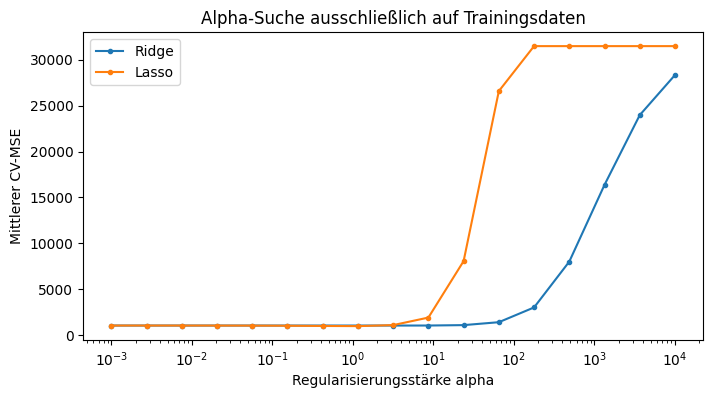

In [24]:
# Logarithmische Skala: sowohl sehr kleine als auch sehr große Werte testen.
alphas = np.logspace(-3, 4, 17)
optimale = {}
plt.figure(figsize=(8, 4))

for name in ["Ridge", "Lasso"]:
    mittel = []
    for alpha in alphas:
        mse_pro_fold = cv_mse(X_r_train, y_r_train, art=name, alpha=float(alpha))
        mittel.append(mse_pro_fold.mean())
    optimale[name] = float(alphas[np.argmin(mittel)])
    plt.semilogx(alphas, mittel, marker=".", label=name)
    print(name, "bestes alpha:", round(optimale[name], 4))

plt.xlabel("Regularisierungsstärke alpha")
plt.ylabel("Mittlerer CV-MSE")
plt.title("Alpha-Suche ausschließlich auf Trainingsdaten")
plt.legend()
plt.show()

## 21. Finale Modelle und unabhängiger Test

Wir trainieren Ridge und Lasso mit den zuvor ausgewählten
Einstellungen erneut auf den vollständigen Trainingsdaten.

Anschließend bewerten wir die Prognosen auf den
bisher nicht verwendeten Testdaten.

In [25]:
# Nach der Modellwahl: beide Modelle neu auf den gesamten Trainingsdaten lernen.
ridge_final = regression_trainieren(X_r_train, y_r_train, art="Ridge", alpha=optimale["Ridge"])
lasso_final = regression_trainieren(X_r_train, y_r_train, art="Lasso", alpha=optimale["Lasso"])

for name, modell in [("Ridge", ridge_final), ("Lasso", lasso_final)]:
    y_hat = regression_vorhersagen(modell, X_r_test)
    print(name,
          "Test-MSE:", round(mean_squared_error(y_r_test, y_hat), 2),
          "Test-R²:", round(r2_score(y_r_test, y_hat), 3))

Ridge Test-MSE: 1124.65 Test-R²: 0.962
Lasso Test-MSE: 1040.22 Test-R²: 0.965


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: divide by zero encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: overflow encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: invalid value encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: divide by zero encountered in matmul
  gram = Z.T @ Z
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: overflow encountered in matmul
  gram = Z.T @ Z
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: inval

## 22. Koeffizientenpfade

Wenn alpha größer wird, schrumpfen die geschätzten Gewichte.

Bei Lasso verschwinden manche Gewichte vollständig.
Ridge macht sie üblicherweise kleiner, aber nicht genau null.

/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: divide by zero encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: overflow encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: invalid value encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: divide by zero encountered in matmul
  gram = Z.T @ Z
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: overflow encountered in matmul
  gram = Z.T @ Z
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:17: RuntimeWarning: inval

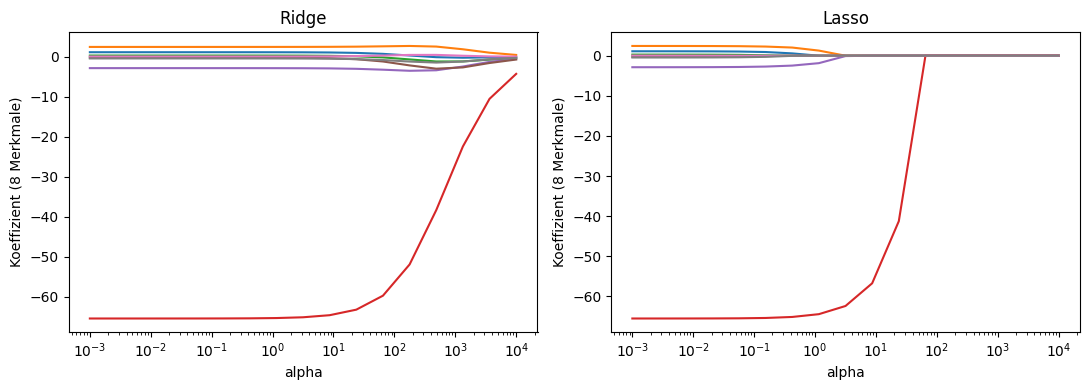

In [26]:
# Die Werte verändern sich entlang der Regularisierungsstärke.
# Zur Übersichtlichkeit zeigen wir nur die ersten acht der 60 Koeffizienten.
fig, achsen = plt.subplots(1, 2, figsize=(11, 4))
for achse, name in zip(achsen, ["Ridge", "Lasso"]):
    pfad = []
    for alpha in alphas:
        mod = regression_trainieren(X_r_train, y_r_train, art=name, alpha=float(alpha))
        pfad.append(mod["koeff"][:8])
    achse.semilogx(alphas, np.asarray(pfad))
    achse.set_title(name)
    achse.set_xlabel("alpha")
    achse.set_ylabel("Koeffizient (8 Merkmale)")
plt.tight_layout()
plt.show()

## 23. Lernkurve

Eine Lernkurve zeigt, ob zusätzliche Trainingsbeobachtungen
die Modellleistung verbessern könnten.

Wir messen Trainings- und Cross-Validation-MSE
für verschiedene Datenmengen.

/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: divide by zero encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: overflow encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:13: RuntimeWarning: invalid value encountered in matmul
  koeff = np.linalg.solve(Z.T @ Z + alpha * np.eye(p), Z.T @ ziel)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: divide by zero encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: overflow encountered in matmul
  return (X - modell["mittel"]) / modell["st

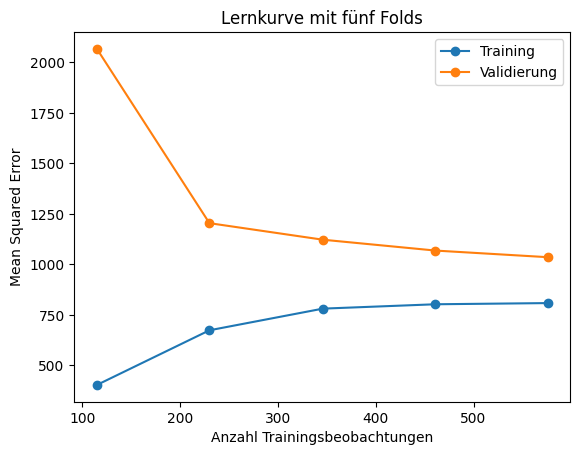

In [27]:
# Verschiedene Trainingsgrößen mit den GLEICHEN fünf CV-Folds vergleichen.
anteile = np.linspace(0.2, 1.0, 5)
train_fehler, val_fehler, groessen = [], [], []
for anteil in anteile:
    mse_tr, mse_val = [], []
    for train_idx, val_idx in kfold_aufteilen(len(y_r_train), 5):
        n_verwendet = max(2, int(round(len(train_idx) * anteil)))
        subset = train_idx[:n_verwendet]
        mod = regression_trainieren(X_r_train[subset], y_r_train[subset],
                                    art="Ridge", alpha=optimale["Ridge"])
        mse_tr.append(mean_squared_error(y_r_train[subset],
                                        regression_vorhersagen(mod, X_r_train[subset])))
        mse_val.append(mean_squared_error(y_r_train[val_idx],
                                         regression_vorhersagen(mod, X_r_train[val_idx])))
    groessen.append(n_verwendet)
    train_fehler.append(np.mean(mse_tr))
    val_fehler.append(np.mean(mse_val))

plt.plot(groessen, train_fehler, marker="o", label="Training")
plt.plot(groessen, val_fehler, marker="o", label="Validierung")
plt.xlabel("Anzahl Trainingsbeobachtungen")
plt.ylabel("Mean Squared Error")
plt.title("Lernkurve mit fünf Folds")
plt.legend()
plt.show()

## 24. AIC und BIC (optionale Vertiefung)

AIC und BIC kombinieren Anpassungsfehler und Modellkomplexität. Hier berechnen
wir eine **didaktische Näherung** für Gauß-Regressionen mit geschätzter Varianz:

- Gemeinsamer Anpassungsterm: `n * log(RSS / n)`.
- Ridge: effektive Freiheitsgrade über die Eigenwerte der Trainingsdatenmatrix.
- Lasso: Zahl der von Null verschiedenen Koeffizienten plus Achsenabschnitt.

Die Formeln sind bewusst vereinfachte Orientierungshilfen. **Penalisierte
AIC/BIC-Auswertungen sind methodisch anspruchsvoller und nicht direkt
mit vollständiger Maximum-Likelihood-Modellselektion gleichzusetzen.**
Wir verwenden keine Testdaten zur Auswahl.

In [28]:
def aic_bic(y, vorhersage, k):
    n = len(y)
    rss = max(float(np.sum((np.asarray(y) - np.asarray(vorhersage))**2)), 1e-12)
    return n * np.log(rss/n) + 2*k, n * np.log(rss/n) + k*np.log(n)

# Ridge: effektive Freiheitsgrade = 1 + Summe(lambda/(lambda + alpha)).
# lambda sind die Eigenwerte von Z.T @ Z (Z = standardisierte Trainingsdaten).
Z_train = (X_r_train - ridge_final["mittel"]) / ridge_final["streuung"]
eigenwerte = np.maximum(np.linalg.eigvalsh(Z_train.T @ Z_train), 0)
k_ridge = 1 + np.sum(eigenwerte / (eigenwerte + optimale["Ridge"]))

# Lasso: Zahl der aktiven Koeffizienten plus Intercept (grobe Näherung).
k_lasso = 1 + np.count_nonzero(np.abs(lasso_final["koeff"]) > 1e-8)

for name, modell, k in [
    ("Ridge", ridge_final, k_ridge),
    ("Lasso", lasso_final, k_lasso)
]:
    ergebnis = aic_bic(y_r_train, regression_vorhersagen(modell, X_r_train), k)
    print(name, "effektive Parameter (Näherung):", round(float(k), 1),
          "AIC/BIC (Näherung):", np.round(ergebnis, 1))

Ridge effektive Parameter (Näherung): 60.7 AIC/BIC (Näherung): [4960.2 5238.2]
Lasso effektive Parameter (Näherung): 31.0 AIC/BIC (Näherung): [4943.6 5085.6]


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/955402837.py:9: RuntimeWarning: divide by zero encountered in matmul
  eigenwerte = np.maximum(np.linalg.eigvalsh(Z_train.T @ Z_train), 0)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/955402837.py:9: RuntimeWarning: overflow encountered in matmul
  eigenwerte = np.maximum(np.linalg.eigvalsh(Z_train.T @ Z_train), 0)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/955402837.py:9: RuntimeWarning: invalid value encountered in matmul
  eigenwerte = np.maximum(np.linalg.eigvalsh(Z_train.T @ Z_train), 0)
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: divide by zero encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: overflow encountered in matmul
  return (X - modell["mittel"]) / modell[

## 25. Welche Merkmale behält Lasso?

Ein Gewicht von genau 0 bedeutet, dass das Merkmal
in diesem Modell keinen linearen Beitrag liefert.

Das beweist nicht, dass das Merkmal in der Realität
unwichtig ist.

In [29]:
# Ein Koeffizient von exakt 0 ist im Lasso-Modell ausgeschaltet.
gewichte = lasso_final["koeff"]
print("Von 60 Merkmalen behalten:", np.count_nonzero(np.abs(gewichte) > 1e-8))
print("Größte absolute Koeffizienten:")
print(pd.Series(gewichte, index=[f"x{i}" for i in range(60)]).abs().nlargest(10))

Von 60 Merkmalen behalten: 30
Größte absolute Koeffizienten:
x30    84.311006
x50    74.909606
x3     64.406904
x16    47.759917
x36    44.318451
x12    40.798951
x43    38.357090
x34    36.425874
x28    34.863093
x24    31.344793
dtype: float64


## 26. Zusammenfassung und Übungsaufgaben

1. **Schwellenwert:** Was passiert mit Recall und Precision, wenn die Grenze sinkt?
2. **Klassenungleichgewicht:** Warum sind 80 % Accuracy nicht immer gut?
3. **Datentrennung:** Warum dürfen Schwellenwerte nicht anhand der Testdaten gewählt werden?
4. **Klassifikation:** Vergleiche die logistische Regression mit dem selbstgebauten Baumensemble.
5. **Regression:** Was passiert mit Ridge- und Lasso-Gewichten, wenn `alpha` steigt?
6. **Cross-Validation:** Warum wird die Standardisierung in jedem Trainingsfold neu berechnet?
7. **Vertiefung:** Verändere `scale=30` in der Erzeugung von `y_r` und wiederhole die Lernkurve.

**Merksatz:** Saubere Trennung von Daten und verständliche Modellannahmen sind
wichtiger als die Anzahl der verwendeten Bibliotheken.

In [30]:
# Zum Abschluss: wichtige Voraussetzungen automatisch prüfen.
assert len(y_k_train) + len(y_k_val) + len(y_k_test) == 600
assert sum(np.bincount(y_k)) == 600
assert 0 < beste_schwelle < 1
assert np.isclose(np.sum(wald["wichtigkeit"]), 1.0)
assert np.isfinite(mean_squared_error(y_r_test, regression_vorhersagen(ridge_final, X_r_test)))
assert np.isfinite(mean_squared_error(y_r_test, regression_vorhersagen(lasso_final, X_r_test)))
print("Alle 27 Codezellen und die abschließenden Plausibilitätsprüfungen sind vorbereitet.")

Alle 27 Codezellen und die abschließenden Plausibilitätsprüfungen sind vorbereitet.


/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: divide by zero encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: overflow encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
/var/folders/nw/k_k0_cbj7vl_npdmryvhl53c0000gn/T/ipykernel_7342/2978039634.py:40: RuntimeWarning: invalid value encountered in matmul
  return (X - modell["mittel"]) / modell["streuung"] @ modell["koeff"] + modell["intercept"]
